In [1]:
import os
import glob
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import torch
from torchvision.utils import save_image
import os
import torch.nn as nn
import torch.nn.functional as F

In [2]:
# Create a folder to save our visual checks
os.makedirs("cyclegan_color_checks", exist_ok=True)

In [ ]:
# --- CONFIGURATION ---
class Config:
    # Update these if your internal folder structure is different
    # Assuming structure: /kaggle/input/sarakshi-data/CycleGAN_Data/CF and .../FAF
    TRAIN_DIR_CF = '' 
    TRAIN_DIR_FAF = ''
    
    IMG_SIZE = 256      # The size we feed into the GAN
    LOAD_SIZE = 286     # Resize to this first, then crop (Jitter)
    BATCH_SIZE = 1      # CycleGAN standard is often 1, but P100 can handle 4-8 at 256px
    NUM_WORKERS = 2     # Kaggle usually gives 2 or 4 CPU cores
    
    # Normalization for GANs ([-1, 1] range)
    MEAN = [0.5, 0.5, 0.5]
    STD = [0.5, 0.5, 0.5]

In [4]:
# --- CUSTOM DATASET CLASS ---
class SarakshiDataset(Dataset):
    def __init__(self, root_cf, root_faf, transform=None, mode='train'):
        self.transform = transform
        
        # 1. Get all image paths
        self.cf_images = sorted(glob.glob(os.path.join(root_cf, '*.*')))
        self.faf_images = sorted(glob.glob(os.path.join(root_faf, '*.*')))
        
        # 2. Filter out small images (Safety Step)
        self.cf_images = self._filter_bad_images(self.cf_images, min_size=Config.LOAD_SIZE)
        self.faf_images = self._filter_bad_images(self.faf_images, min_size=Config.LOAD_SIZE)
        
        # 3. Handle dataset imbalance
        self.len_cf = len(self.cf_images)
        self.len_faf = len(self.faf_images)
        self.max_len = max(self.len_cf, self.len_faf)
        
        print(f"[{mode.upper()}] CF Images: {self.len_cf} | FAF Images: {self.len_faf}")

    def _filter_bad_images(self, image_list, min_size):
        """Removes images smaller than the crop size to prevent crashing."""
        valid_images = []
        for img_path in image_list:
            try:
                # We open lazy (don't load pixels) just to check size
                with Image.open(img_path) as img:
                    w, h = img.size
                    if w >= min_size and h >= min_size:
                        valid_images.append(img_path)
            except:
                pass # Skip corrupt files
        return valid_images

    def __len__(self):
        return self.max_len

    def __getitem__(self, index):
        # CycleGAN requires Unpaired data.
        # We assume index maps to Domain A (CF), and we pick Domain B (FAF) randomly.
        
        # Get Domain A (CF) - Use modulo to loop if we run out
        cf_path = self.cf_images[index % self.len_cf]
        
        # Get Domain B (FAF) - Random sampling
        faf_index = random.randint(0, self.len_faf - 1)
        faf_path = self.faf_images[faf_index]
        
        cf_img = Image.open(cf_path).convert('RGB')
        faf_img = Image.open(faf_path).convert('L').convert('RGB')
        
        if self.transform:
            cf_img = self.transform(cf_img)
            faf_img = self.transform(faf_img)
            
        return {'A': cf_img, 'B': faf_img}

In [5]:
# --- TRANSFORMS & LOADERS ---
def get_transforms():
    return transforms.Compose([
        transforms.Resize((Config.LOAD_SIZE, Config.LOAD_SIZE), Image.BICUBIC),
        transforms.RandomCrop(Config.IMG_SIZE),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(Config.MEAN, Config.STD)
    ])

# Initialize
dataset = SarakshiDataset(
    Config.TRAIN_DIR_CF, 
    Config.TRAIN_DIR_FAF, 
    transform=get_transforms()
)

dataloader = DataLoader(
    dataset, 
    batch_size=Config.BATCH_SIZE, 
    shuffle=True, 
    num_workers=Config.NUM_WORKERS
)

[TRAIN] CF Images: 315 | FAF Images: 309


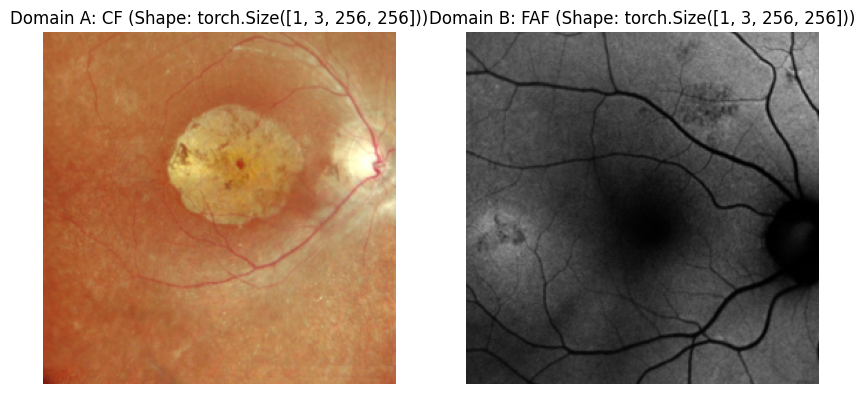

In [8]:
# --- VISUALIZATION CHECK ---
# We must verify normalization is [-1, 1] and images look correct
def show_sample_batch():
    batch = next(iter(dataloader))
    real_A = batch['A'] # CF
    real_B = batch['B'] # FAF
    
    # Denormalize for visualization: (-1, 1) -> (0, 1)
    def denorm(img_tensor):
        return img_tensor * 0.5 + 0.5
    
    plt.figure(figsize=(10, 5))
    
    # Show CF
    plt.subplot(1, 2, 1)
    plt.title(f"Domain A: CF (Shape: {real_A.shape})")
    plt.imshow(denorm(real_A[0]).permute(1, 2, 0))
    plt.axis('off')
    
    # Show FAF
    plt.subplot(1, 2, 2)
    plt.title(f"Domain B: FAF (Shape: {real_B.shape})")
    plt.imshow(denorm(real_B[0]).permute(1, 2, 0))
    plt.axis('off')
    
    plt.show()

# Run the check
show_sample_batch()

In [9]:
# --- COMPONENT 1 & 2: THE GENERATOR (U-Net) ---
class Block(nn.Module):
    def __init__(self, in_channels, out_channels, down=True, act="relu", use_dropout=False):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 4, 2, 1, bias=False, padding_mode="reflect")
            if down
            else nn.ConvTranspose2d(in_channels, out_channels, 4, 2, 1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU() if act == "relu" else nn.LeakyReLU(0.2),
        )
        self.use_dropout = use_dropout
        self.dropout = nn.Dropout(0.5)
    def forward(self, x):
        x = self.conv(x)
        return self.dropout(x) if self.use_dropout else x
    
class UNetGenerator(nn.Module):
    def __init__(self, in_channels=3, features=64):
        super().__init__()
        self.initial_down = nn.Sequential(
            nn.Conv2d(in_channels, features, 4, 2, 1, padding_mode="reflect"),
            nn.LeakyReLU(0.2),
        )
        self.down1 = Block(features, features * 2, down=True, act="leaky")
        self.down2 = Block(features * 2, features * 4, down=True, act="leaky")
        self.down3 = Block(features * 4, features * 8, down=True, act="leaky")
        self.down4 = Block(features * 8, features * 8, down=True, act="leaky")
        self.down5 = Block(features * 8, features * 8, down=True, act="leaky")
        self.down6 = Block(features * 8, features * 8, down=True, act="leaky")
        self.bottleneck = nn.Sequential(
            nn.Conv2d(features * 8, features * 8, 4, 2, 1, padding_mode="reflect"),
            nn.ReLU()
        )
        self.up1 = Block(features * 8, features * 8, down=False, act="relu", use_dropout=True)
        self.up2 = Block(features * 8 * 2, features * 8, down=False, act="relu", use_dropout=True)
        self.up3 = Block(features * 8 * 2, features * 8, down=False, act="relu", use_dropout=True)
        self.up4 = Block(features * 8 * 2, features * 8, down=False, act="relu")
        self.up5 = Block(features * 8 * 2, features * 4, down=False, act="relu")
        self.up6 = Block(features * 4 * 2, features * 2, down=False, act="relu")
        self.up7 = Block(features * 2 * 2, features, down=False, act="relu")
        self.final_up = nn.Sequential(
            nn.ConvTranspose2d(features * 2, in_channels, kernel_size=4, stride=2, padding=1),
            nn.Tanh(),
        )
    def forward(self, x):
        d1 = self.initial_down(x)
        d2 = self.down1(d1)
        d3 = self.down2(d2)
        d4 = self.down3(d3)
        d5 = self.down4(d4)
        d6 = self.down5(d5)
        d7 = self.down6(d6)
        bottleneck = self.bottleneck(d7)
        up1 = self.up1(bottleneck)
        up2 = self.up2(torch.cat([up1, d7], 1))
        up3 = self.up3(torch.cat([up2, d6], 1))
        up4 = self.up4(torch.cat([up3, d5], 1))
        up5 = self.up5(torch.cat([up4, d4], 1))
        up6 = self.up6(torch.cat([up5, d3], 1))
        up7 = self.up7(torch.cat([up6, d2], 1))
        return self.final_up(torch.cat([up7, d1], 1))

# --- COMPONENT 3: THE DISCRIMINATOR (PatchGAN) ---
class Discriminator(nn.Module):
    def __init__(self, input_shape):
        super(Discriminator, self).__init__()
        
        channels, height, width = input_shape

        def discriminator_block(in_filters, out_filters, normalize=True):
            """Returns downsampling layers of each discriminator block"""
            layers = [nn.Conv2d(in_filters, out_filters, 4, stride=2, padding=1)]
            if normalize:
                layers.append(nn.InstanceNorm2d(out_filters))
            layers.append(nn.LeakyReLU(0.2, inplace=True))
            return layers

        self.model = nn.Sequential(
            *discriminator_block(channels, 64, normalize=False),
            *discriminator_block(64, 128),
            *discriminator_block(128, 256),
            *discriminator_block(256, 512),
            nn.ZeroPad2d((1, 0, 1, 0)),
            nn.Conv2d(512, 1, 4, padding=1) 
            # Output is NOT a single number, but a map of numbers (e.g. 16x16)
        )

    def forward(self, img):
        return self.model(img)

# --- COMPONENT 4: INITIALIZATION ---
# GANs are sensitive. We must initialize weights from a Normal distribution.
def weights_init_normal(m):
    classname = m.__class__.__name__
    if 'Conv' in classname:
        torch.nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif 'BatchNorm2d' in classname:
        torch.nn.init.normal_(m.weight.data, 1.0, 0.02)
        torch.nn.init.constant_(m.bias.data, 0.0)

# --- INSTANTIATE MODELS ---
# We need TWO Generators and TWO Discriminators for CycleGAN
input_shape = (3, Config.IMG_SIZE, Config.IMG_SIZE)

# G_AB: Translates Domain A (CF) -> Domain B (FAF)
# Using features=48 as per your optimized pix2pix setup
G_AB = UNetGenerator(in_channels=3, features=48)
# G_BA: Translates Domain B (FAF) -> Domain A (CF)
G_BA = UNetGenerator(in_channels=3, features=48)

# D_A: Distinguishes Real CF vs Fake CF
D_A = Discriminator(input_shape)
# D_B: Distinguishes Real FAF vs Fake FAF
D_B = Discriminator(input_shape)

# Move to GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
G_AB = G_AB.to(device)
G_BA = G_BA.to(device)
D_A = D_A.to(device)
D_B = D_B.to(device)

# Apply weights
G_AB.apply(weights_init_normal)
G_BA.apply(weights_init_normal)
D_A.apply(weights_init_normal)
D_B.apply(weights_init_normal)

print(f"Models initialized successfully on {device}")

Models initialized successfully on cuda


In [10]:
import itertools
import time
import datetime

# --- CONFIGURATION (HYPERPARAMETERS) ---
EPOCHS = 100         # Start with 100. If good, we train more.
DECAY_EPOCHS = 100   # Linear decay of learning rate after EPOCHS
LR = 0.0002          # Standard GAN learning rate
B1 = 0.5             # Adam Beta 1
B2 = 0.999           # Adam Beta 2
LAMBDA_CYC = 5.0    # Cycle consistency weight (Critical for medical images)
LAMBDA_ID = 0.0     # Identity loss weight

# --- LOSS FUNCTIONS ---
criterion_GAN = torch.nn.MSELoss() # Mean Squared Error for GAN loss
criterion_cycle = torch.nn.L1Loss() # L1 Loss (Absolute Error) for consistency
criterion_identity = torch.nn.L1Loss()

# --- OPTIMIZERS ---
# We combine G_AB and G_BA parameters into one optimizer
optimizer_G = torch.optim.Adam(
    itertools.chain(G_AB.parameters(), G_BA.parameters()), lr=LR, betas=(B1, B2)
)
optimizer_D_A = torch.optim.Adam(D_A.parameters(), lr=LR, betas=(B1, B2))
optimizer_D_B = torch.optim.Adam(D_B.parameters(), lr=LR, betas=(B1, B2))

# --- LEARNING RATE SCHEDULER ---
# Keeps LR constant for 'EPOCHS', then decays linearly to 0
class LambdaLR:
    def __init__(self, n_epochs, offset, decay_start_epoch):
        self.n_epochs = n_epochs
        self.offset = offset
        self.decay_start_epoch = decay_start_epoch

    def step(self, epoch):
        return 1.0 - max(0, epoch + self.offset - self.decay_start_epoch) / (
            self.n_epochs - self.decay_start_epoch
        )

lr_scheduler_G = torch.optim.lr_scheduler.LambdaLR(
    optimizer_G, lr_lambda=LambdaLR(EPOCHS + DECAY_EPOCHS, 0, EPOCHS).step
)
lr_scheduler_D_A = torch.optim.lr_scheduler.LambdaLR(
    optimizer_D_A, lr_lambda=LambdaLR(EPOCHS + DECAY_EPOCHS, 0, EPOCHS).step
)
lr_scheduler_D_B = torch.optim.lr_scheduler.LambdaLR(
    optimizer_D_B, lr_lambda=LambdaLR(EPOCHS + DECAY_EPOCHS, 0, EPOCHS).step
)

# --- REPLAY BUFFER (STABILITY TRICK) ---
class ReplayBuffer:
    def __init__(self, max_size=50):
        self.max_size = max_size
        self.data = []

    def push_and_pop(self, data):
        to_return = []
        for element in data.data:
            element = torch.unsqueeze(element, 0)
            if len(self.data) < self.max_size:
                self.data.append(element)
                to_return.append(element)
            else:
                if random.uniform(0, 1) > 0.5:
                    i = random.randint(0, self.max_size - 1)
                    to_return.append(self.data[i].clone())
                    self.data[i] = element
                else:
                    to_return.append(element)
        return torch.cat(to_return)

fake_A_buffer = ReplayBuffer()
fake_B_buffer = ReplayBuffer()

# --- TRAINING FUNCTION ---
def train_cycle_gan():
    prev_time = time.time()
    
    print(f"--- Starting Training on {device} ---")
    
    for epoch in range(EPOCHS):
        for i, batch in enumerate(dataloader):
            
            # Set model input
            real_A = batch['A'].to(device) # Real CF
            real_B = batch['B'].to(device) # Real FAF
            
            # Adversarial Ground Truths (for 70x70 PatchGAN)
            # 1.0 = Real, 0.0 = Fake
            valid = torch.ones(real_A.size(0), 1, 16, 16, requires_grad=False).to(device)
            fake = torch.zeros(real_A.size(0), 1, 16, 16, requires_grad=False).to(device)
            # Note: 16x16 depends on image size 256. If 512, this changes.
            # Actually, let's make it dynamic to avoid bugs if you scale up:
            grid_size = real_A.size(2) // 16 # Approximation for PatchGAN output
            valid = torch.ones(real_A.size(0), 1, 16, 16).to(device) 
            fake = torch.zeros(real_A.size(0), 1, 16, 16).to(device)

            # ------------------
            #  Train Generators
            # ------------------
            G_AB.train()
            G_BA.train()
            optimizer_G.zero_grad()

            # 1. Identity Loss
            # G_AB(B) should equal B if B is already FAF
            loss_id_A = criterion_identity(G_BA(real_A), real_A)
            loss_id_B = criterion_identity(G_AB(real_B), real_B)
            loss_identity = (loss_id_A + loss_id_B) / 2

            # 2. GAN Loss
            fake_B = G_AB(real_A) # CF -> Fake FAF
            loss_GAN_AB = criterion_GAN(D_B(fake_B), valid) # Trick D_B into thinking it's real
            
            fake_A = G_BA(real_B) # FAF -> Fake CF
            loss_GAN_BA = criterion_GAN(D_A(fake_A), valid) # Trick D_A into thinking it's real
            
            loss_GAN = (loss_GAN_AB + loss_GAN_BA) / 2

            # 3. Cycle Consistency Loss
            rec_A = G_BA(fake_B) # CF -> Fake FAF -> Reconstructed CF
            loss_cycle_A = criterion_cycle(rec_A, real_A)
            
            rec_B = G_AB(fake_A) # FAF -> Fake CF -> Reconstructed FAF
            loss_cycle_B = criterion_cycle(rec_B, real_B)
            
            loss_cycle = (loss_cycle_A + loss_cycle_B) / 2

            # Total Generator Loss
            loss_G = loss_GAN + (LAMBDA_CYC * loss_cycle) + (LAMBDA_ID * loss_identity)
            loss_G.backward()
            optimizer_G.step()

            # -----------------------
            #  Train Discriminator A
            # -----------------------
            optimizer_D_A.zero_grad()
            # Real loss
            loss_real = criterion_GAN(D_A(real_A), valid)
            # Fake loss (using Replay Buffer)
            fake_A_ = fake_A_buffer.push_and_pop(fake_A)
            loss_fake = criterion_GAN(D_A(fake_A_.detach()), fake)
            # Total loss
            loss_D_A = (loss_real + loss_fake) / 2
            loss_D_A.backward()
            optimizer_D_A.step()

            # -----------------------
            #  Train Discriminator B
            # -----------------------
            optimizer_D_B.zero_grad()
            # Real loss
            loss_real = criterion_GAN(D_B(real_B), valid)
            # Fake loss (using Replay Buffer)
            fake_B_ = fake_B_buffer.push_and_pop(fake_B)
            loss_fake = criterion_GAN(D_B(fake_B_.detach()), fake)
            # Total loss
            loss_D_B = (loss_real + loss_fake) / 2
            loss_D_B.backward()
            optimizer_D_B.step()

            # ------------------
            #  Log Progress
            # ------------------
            # Every 100 batches, print status
            if i % 100 == 0:
                batches_done = epoch * len(dataloader) + i
                batches_left = EPOCHS * len(dataloader) - batches_done
                time_left = datetime.timedelta(seconds=batches_left * (time.time() - prev_time))
                prev_time = time.time()
                
                print(f"[Epoch {epoch}/{EPOCHS}] [Batch {i}/{len(dataloader)}] "
                      f"[D loss: {(loss_D_A + loss_D_B).item():.4f}] "
                      f"[G loss: {loss_G.item():.4f}] "
                      f"ETA: {time_left}")
                
                # --- NEW: VISUAL COLOR LEAKAGE CHECK ---
                # Un-normalize from [-1, 1] back to [0, 1] for saving
                save_image(real_A.data * 0.5 + 0.5, f"cyclegan_color_checks/epoch_{epoch}_1_Real_CF.png")
                save_image(fake_B.data * 0.5 + 0.5, f"cyclegan_color_checks/epoch_{epoch}_2_Fake_FAF.png")
                save_image(real_B.data * 0.5 + 0.5, f"cyclegan_color_checks/epoch_{epoch}_3_Real_FAF.png")
                      
        # Update learning rates
        lr_scheduler_G.step()
        lr_scheduler_D_A.step()
        lr_scheduler_D_B.step()
        
        # --- SAVE CHECKPOINT ---
        # Save model every 5 epochs so we don't lose progress
        if epoch % 5 == 0:
            torch.save(G_AB.state_dict(), f"G_AB_{epoch}.pth")
            torch.save(G_BA.state_dict(), f"G_BA_{epoch}.pth")
            print(f"Saved Checkpoint for Epoch {epoch}")

# Run Training
train_cycle_gan()

--- Starting Training on cuda ---
[Epoch 0/100] [Batch 0/315] [D loss: 4.5603] [G loss: 5.2636] ETA: 11:52:58.600931
[Epoch 0/100] [Batch 100/315] [D loss: 0.5586] [G loss: 0.9275] ETA: 4 days, 8:17:17.073755
[Epoch 0/100] [Batch 200/315] [D loss: 0.4683] [G loss: 1.3020] ETA: 4 days, 8:23:34.815569
[Epoch 0/100] [Batch 300/315] [D loss: 0.3329] [G loss: 1.1824] ETA: 4 days, 8:00:12.854004
Saved Checkpoint for Epoch 0
[Epoch 1/100] [Batch 0/315] [D loss: 0.5170] [G loss: 1.0209] ETA: 20:07:33.088338
[Epoch 1/100] [Batch 100/315] [D loss: 0.5599] [G loss: 0.9709] ETA: 4 days, 7:29:52.956852
[Epoch 1/100] [Batch 200/315] [D loss: 0.4598] [G loss: 0.8063] ETA: 4 days, 7:12:48.481203
[Epoch 1/100] [Batch 300/315] [D loss: 0.5878] [G loss: 1.1468] ETA: 4 days, 6:53:54.556160
[Epoch 2/100] [Batch 0/315] [D loss: 0.4961] [G loss: 0.8447] ETA: 17:12:29.891953
[Epoch 2/100] [Batch 100/315] [D loss: 0.4361] [G loss: 0.5885] ETA: 4 days, 6:28:38.119535
[Epoch 2/100] [Batch 200/315] [D loss: 0.559